# Exploración del dataset de diamantes

In [1]:
import os
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image

from utilidades import calcular_media_desviacion, crear_dataloaders, desnormalizar, MEDIA, DESVIACION

torch.manual_seed(42)

## Tamaño original de las imágenes

In [2]:
anchos = []
altos = []
for clase in sorted(os.listdir('dataset')):
    for fichero in os.listdir(os.path.join('dataset', clase)):
        with Image.open(os.path.join('dataset', clase, fichero)) as imagen:
            anchos.append(imagen.width)
            altos.append(imagen.height)

print(f'Número de imágenes: {len(anchos)}')
print(f'Ancho -> mínimo: {min(anchos)} | máximo: {max(anchos)} | medio: {np.mean(anchos):.0f}')
print(f'Alto  -> mínimo: {min(altos)} | máximo: {max(altos)} | medio: {np.mean(altos):.0f}')

Número de imágenes: 23737
Ancho -> mínimo: 491 | máximo: 601 | medio: 587
Alto  -> mínimo: 381 | máximo: 600 | medio: 463


## Carga de los conjuntos de entrenamiento, validación y test

In [3]:
tam_imagen = 128
tam_lote = 32

dataloader_entrenamiento, dataloader_validacion, dataloader_test, clases = crear_dataloaders('datos', tam_imagen, tam_lote)

print(f'Nombre de las etiquetas: {clases}')

Nombre de las etiquetas: ['cushion', 'emerald', 'heart', 'oval', 'pear', 'princess', 'round']

## Distribución de imágenes por clase

Entrenamiento | total: 16611 | cushion: 2373 | emerald: 2373 | heart: 2373 | oval: 2373 | pear: 2373 | princess: 2373 | round: 2373
Validación    | total:  3556 | cushion: 508 | emerald: 508 | heart: 508 | oval: 508 | pear: 508 | princess: 508 | round: 508
Test          | total:  3570 | cushion: 510 | emerald: 510 | heart: 510 | oval: 510 | pear: 510 | princess: 510 | round: 510


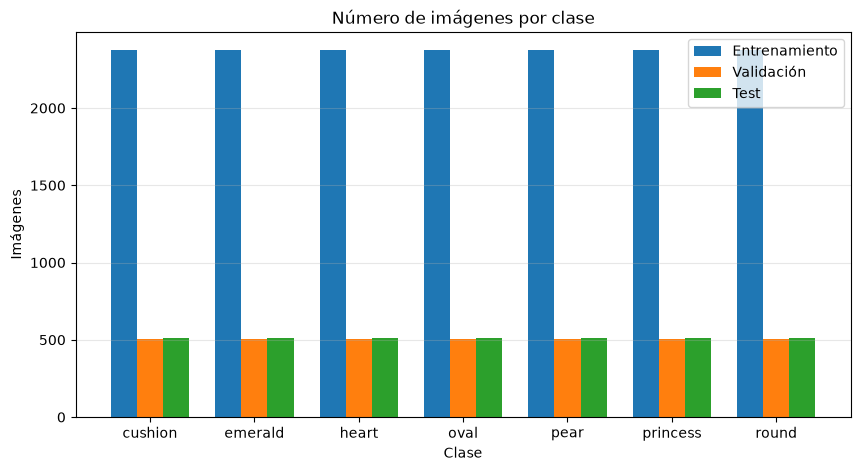

In [4]:
conjuntos = {
    'Entrenamiento': dataloader_entrenamiento.dataset,
    'Validación': dataloader_validacion.dataset,
    'Test': dataloader_test.dataset,
}

for nombre, dataset in conjuntos.items():
    recuento = Counter(dataset.targets)
    print(f'{nombre:13s} | total: {len(dataset):5d} | ' + ' | '.join(f'{clases[i]}: {recuento[i]}' for i in range(len(clases))))

posiciones = np.arange(len(clases))
ancho_barra = 0.25

plt.figure(figsize=(10, 5))
for desplazamiento, (nombre, dataset) in enumerate(conjuntos.items()):
    recuento = Counter(dataset.targets)
    plt.bar(posiciones + desplazamiento * ancho_barra, [recuento[i] for i in range(len(clases))], ancho_barra, label=nombre)

plt.xticks(posiciones + ancho_barra, clases)
plt.title('Número de imágenes por clase')
plt.xlabel('Clase')
plt.ylabel('Imágenes')
plt.legend()
plt.grid(True, axis='y', alpha=0.3)
plt.show()

## Visualización de un lote de entrenamiento

Dimensiones del batch de imágenes: torch.Size([32, 3, 128, 128])
Dimensiones del batch de etiquetas: torch.Size([32])


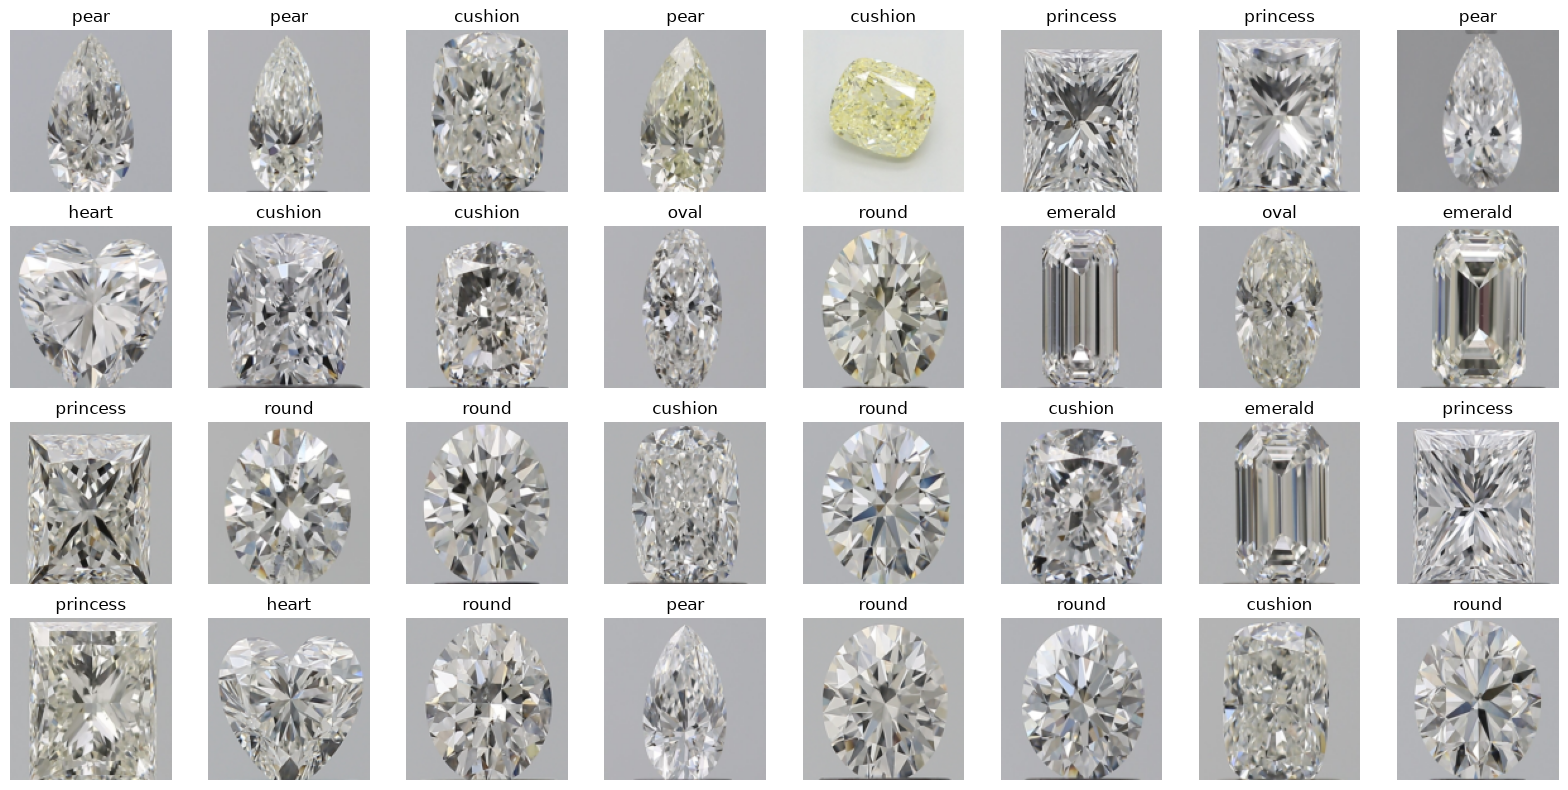

In [5]:
dataiter = iter(dataloader_entrenamiento)
imagenes, etiquetas = next(dataiter)

print(f'Dimensiones del batch de imágenes: {imagenes.size()}')
print(f'Dimensiones del batch de etiquetas: {etiquetas.size()}')

plt.figure(figsize=(16, 8))
for i in range(32):
    plt.subplot(4, 8, i + 1)
    plt.imshow(desnormalizar(imagenes[i]))
    plt.title(clases[etiquetas[i].item()])
    plt.axis('off')
plt.tight_layout()
plt.show()

## Un ejemplo de cada clase

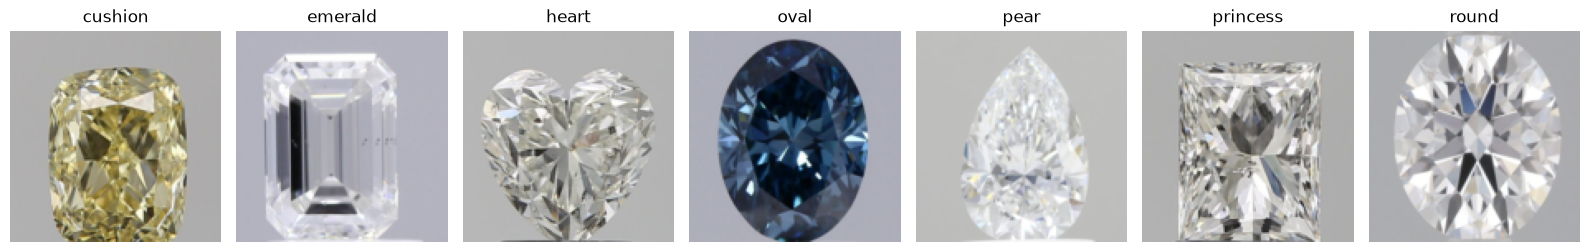

In [6]:
dataset_entrenamiento = dataloader_entrenamiento.dataset

plt.figure(figsize=(16, 3))
for indice_clase, clase in enumerate(clases):
    indice_imagen = dataset_entrenamiento.targets.index(indice_clase)
    imagen, _ = dataset_entrenamiento[indice_imagen]
    plt.subplot(1, len(clases), indice_clase + 1)
    plt.imshow(desnormalizar(imagen))
    plt.title(clase)
    plt.axis('off')
plt.tight_layout()
plt.show()

## Media y desviación típica del conjunto de entrenamiento

In [7]:
media, desviacion = calcular_media_desviacion('datos/training', tam_imagen)

print(f'Media calculada:      {[round(valor, 4) for valor in media.tolist()]}')
print(f'Desviación calculada: {[round(valor, 4) for valor in desviacion.tolist()]}')
print(f'Media usada en Normalize:      {MEDIA}')
print(f'Desviación usada en Normalize: {DESVIACION}')

Media calculada:      [0.6705, 0.6694, 0.6696]
Desviación calculada: [0.128, 0.1281, 0.1322]
Media usada en Normalize:      [0.6705, 0.6694, 0.6696]
Desviación usada en Normalize: [0.128, 0.1281, 0.1322]
